# Proiectul 2 · Varianta 1: Furnici sau albine?
### Clasificare de imagini cu transfer learning (ResNet18)

**Autor:** Georgiana Stan

---

**Rezumat.** Am la dispoziție aproximativ 400 de poze cu furnici și albine: 244 pentru antrenare și 153 pentru validare. Sunt prea puține ca să antrenez de la zero o rețea convoluțională, așa că pornesc de la **ResNet18 pre-antrenat pe ImageNet** (1,2 milioane de poze) și îl adaptez la cele 2 clase ale mele. Compar două strategii, **feature extraction** și **fine-tuning**, cu un **baseline** simplu. Cel mai bun model ajunge la **94,8%** acuratețe pe validare, față de 45,8% cât obține baseline-ul.

### Cuprins
| # | Secțiune | Conținut |
|---|-----|--------|
| 1 | Problema | 2 clase, o decizie clară |
| – | Pregătire | biblioteci și funcții ajutătoare |
| 2 | Datele | obținere, verificare, explorare, augmentare |
| 3 | Baseline | „ghicesc mereu clasa mare” |
| 4 | Modele | feature extraction vs. fine-tuning |
| 5 | Evaluare | matrice de confuzie, precizie/recall, analiza greșelilor |
| 6 | Demo | salvez modelul și îl folosesc pentru predicții |
| 7 | Concluzii | ce a mers, ce nu, ce aș face mai departe |

## 1 · Problema

**Întrebarea:** primind o fotografie cu o insectă, este o **furnică** (`ants`) sau o **albină** (`bees`)?

- **Tipul problemei:** clasificare de imagini, cu **2 clase** și o singură etichetă pe poză.
- **La ce ar folosi:** de exemplu, într-o aplicație pentru apicultori sau pentru copii care învață despre insecte: faci o poză, iar aplicația spune ce insectă este.
- **Metrica principală:** **acuratețea pe validare**. Clasele sunt aproape echilibrate, deci acuratețea e relevantă. Mă uit și la **precizie** și **recall** pentru fiecare clasă și la **matricea de confuzie**.
- **Ce înseamnă „bine”:** modelul trebuie să depășească clar baseline-ul (în jur de 50%). Ținta mea este **peste 90%** pe validare.

## Pregătire: biblioteci și funcții ajutătoare
În această parte instalez bibliotecile care lipsesc și definesc funcțiile pe care le folosesc în restul proiectului. Aici nu se antrenează încă niciun model.

### Biblioteci folosite

| Bibliotecă | La ce o folosesc |
|---|---|
| `torch` (PyTorch) | rețele neuronale: modele, antrenare, calcule pe GPU |
| `torchvision` | modele pre-antrenate (ResNet18), încărcarea pozelor din foldere, transformări pentru imagini |
| `numpy` | calcule cu vectori și matrici |
| `pandas` | tabele (numărul de poze, rezultate) |
| `matplotlib` | grafice și afișarea pozelor |
| `scikit-learn` | metrici de evaluare: matricea de confuzie, precizie, recall |
| `pillow` (PIL) | deschiderea fișierelor imagine (JPG, PNG) |
| `requests` | descărcarea fișierelor de pe internet |

Celula următoare verifică ce biblioteci lipsesc și le instalează doar pe acelea, cu `pip`. Dacă sunt toate instalate, afișează doar versiunile lor.

In [1]:
import importlib.util, importlib.metadata, subprocess, sys

# numele cu care IMPORTĂM biblioteca  ->  numele cu care o INSTALĂM cu pip (uneori diferă!)
NECESARE = {
    "torch": "torch",
    "torchvision": "torchvision",
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "PIL": "pillow",
    "requests": "requests",
}

def versiune(pachet):
    """Versiunea instalată a unui pachet, ca tuplu (major, minor). (0, 0) dacă nu e instalat."""
    try:
        return tuple(int(x) for x in importlib.metadata.version(pachet).split("+")[0].split(".")[:2])
    except Exception:
        return (0, 0)

# find_spec(nume) întoarce None dacă biblioteca NU e instalată
lipsa = [pip for modul, pip in NECESARE.items() if importlib.util.find_spec(modul) is None]

# Avem nevoie de torchvision >= 0.15 (acolo a apărut models.get_model, pe care îl folosim)
if "torchvision" not in lipsa and versiune("torchvision") < (0, 15):
    lipsa.append("torchvision>=0.15")

if lipsa:
    print("📦 Instalez:", ", ".join(lipsa), "(poate dura câteva minute)")
    # echivalentul comenzii din terminal:  pip install -q --upgrade torch torchvision ...
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *lipsa])
    print("✅ Instalare terminată. Dacă apar erori la importuri, repornesc kernel-ul și rulez din nou.")
else:
    print("✅ Toate bibliotecile sunt deja instalate.")

# Afișăm versiunile (util dacă ceva nu merge și ceri ajutor)
for pachet in ["torch", "torchvision", "scikit-learn", "pandas"]:
    print(f"   {pachet:<13} {importlib.metadata.version(pachet)}")

✅ Toate bibliotecile sunt deja instalate.
   torch         2.14.1+cu130
   torchvision   0.29.1+cu130
   scikit-learn  1.6.1
   pandas        2.2.3


### Importuri, seed și device

- **Seed-ul** fixează punctul de pornire al numerelor aleatoare. De el depind amestecarea pozelor, augmentarea și greutățile inițiale ale stratului nou. Cu același seed (42), rezultatele ies aproape la fel la fiecare rulare, așa că pot compara corect experimentele între ele.
- **Device-ul** este locul unde se fac calculele: placa video (`cuda`, mult mai rapidă) sau procesorul (`cpu`).

In [2]:
# --- biblioteci standard Python ---
import os, io, random, zipfile, tarfile, hashlib, shutil, time   # fișiere, arhive, amprente, timp

# --- biblioteci pentru date și grafice ---
import numpy as np                    # calcule cu vectori
import pandas as pd                   # tabele
import matplotlib.pyplot as plt       # grafice
import requests                       # descărcări de pe internet
from PIL import Image                 # deschiderea pozelor

# --- PyTorch ---
import torch
import torch.nn as nn                                       # straturi (ex. nn.Linear) și funcții de loss
from torchvision import datasets, transforms, models        # seturi de poze, transformări, modele pre-antrenate

# --- metrici de evaluare ---
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

plt.rcParams["figure.figsize"] = (8, 4.5)                   # mărimea implicită a graficelor

SEED = 42
def fixeaza_seed(seed=SEED):
    """Fixează toate generatoarele de numere aleatoare (Python, NumPy, PyTorch)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
fixeaza_seed()

# Folosim GPU-ul dacă există, altfel procesorul
device = "cuda" if torch.cuda.is_available() else "cpu"
# NUM_WORKERS = câte procese încarcă pozele în paralel cu antrenarea (pe GPU ajută, pe CPU nu)
NUM_WORKERS = 2 if device == "cuda" else 0
print("Rulăm pe:", device, "| PyTorch", torch.__version__)
if device == "cpu":
    print("⚠️ Nu există GPU: antrenarea pe CPU va fi mai lentă.")

Rulăm pe: cuda | PyTorch 2.14.1+cu130


### Funcții pentru antrenare și evaluare

`antreneaza` și `evalueaza` au același rol ca `.fit()` și `.score()` din scikit-learn.

**Cum învață rețeaua**, la fiecare pas:
1. primește un **lot (batch)** de 16 poze și calculează un scor pentru fiecare clasă (**forward**);
2. **funcția de loss** (`CrossEntropyLoss`) măsoară cât de departe sunt scorurile de etichetele corecte;
3. **backward** calculează **gradienții**: în ce direcție trebuie schimbată fiecare greutate ca loss-ul să scadă;
4. **optimizatorul** `Adam` modifică greutățile cu un pas mic. Mărimea pasului este **rata de învățare (`lr`)**.

O trecere prin toate pozele de antrenare se numește **epocă**. După fiecare epocă calculez **acuratețea pe validare**, adică pe poze pe care modelul nu le-a folosit la antrenare. Ea arată cât de bine **generalizează** modelul. Dacă acuratețea pe train ajunge mult peste cea pe validare, modelul a început să memoreze pozele de antrenare (**overfitting**).

In [3]:
# Media și deviația standard ale culorilor (R, G, B) din ImageNet.
# Modelele pre-antrenate au văzut pozele normalizate cu aceste valori, deci le normalizăm la fel.
MEDIE, DEVIATIE = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

def antreneaza(model, train_loader, epoci=1, lr=1e-3, val_loader=None):
    """Antrenează modelul și întoarce (model, istoric). Istoricul = tabel cu loss/acuratețe pe fiecare epocă."""
    model.to(device)                                              # mutăm modelul pe GPU/CPU
    # Optimizăm DOAR parametrii neînghețați (requires_grad=True)
    parametri = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(parametri, lr=lr)
    loss_fn = nn.CrossEntropyLoss()                               # loss-ul standard pentru clasificare
    istoric = []
    for epoca in range(1, epoci + 1):
        start = time.time()
        model.train()                                             # modul „antrenare” (contează pentru BatchNorm/Dropout)
        total = corecte = 0
        suma_loss = 0.0
        for x, y in train_loader:                                 # x = lot de poze [16, 3, 224, 224], y = etichete [16]
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()                                 # ștergem gradienții de la lotul anterior
            iesire = model(x)                                     # forward: un scor pentru fiecare clasă
            loss = loss_fn(iesire, y)                             # cât de greșit e modelul pe acest lot
            loss.backward()                                       # backward: calculăm gradienții
            optimizer.step()                                      # actualizăm greutățile
            suma_loss += loss.item() * len(y)
            corecte += (iesire.argmax(1) == y).sum().item()       # argmax = clasa cu scorul cel mai mare
            total += len(y)
        rand = {"epoca": epoca, "loss": suma_loss / total, "acc_train": corecte / total}
        mesaj = f"epoca {epoca}: loss {rand['loss']:.3f} | acuratețe train {rand['acc_train']:.3f}"
        if val_loader is not None:
            rand["acc_val"] = evalueaza(model, val_loader)[0]
            mesaj += f" | acuratețe validare {rand['acc_val']:.3f}"
        print(mesaj + f"  ({time.time() - start:.0f}s)")
        istoric.append(rand)
    return model, pd.DataFrame(istoric)

@torch.no_grad()                    # la evaluare nu avem nevoie de gradienți: mai rapid, mai puțină memorie
def evalueaza(model, loader):
    """Întoarce (acuratețe, etichete reale, predicții, probabilități pentru fiecare clasă)."""
    model.to(device).eval()         # modul „evaluare”: fără Dropout, BatchNorm folosește statisticile învățate
    y_true, y_pred, probs = [], [], []
    for x, y in loader:
        p = model(x.to(device)).softmax(1).cpu()       # softmax transformă scorurile în probabilități (sumă = 100%)
        probs.append(p)
        y_pred += p.argmax(1).tolist()
        y_true += y.tolist()
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return (y_true == y_pred).mean(), y_true, y_pred, torch.cat(probs).numpy()

def deseneaza_istoric(istorice):
    """Desenează curbele de învățare. istorice = {"nume experiment": tabelul întors de antreneaza}."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    for nume, ist in istorice.items():
        ax1.plot(ist["epoca"], ist["loss"], marker="o", label=nume)
        linie, = ax2.plot(ist["epoca"], ist["acc_val"], marker="o", label=f"{nume} · validare")
        ax2.plot(ist["epoca"], ist["acc_train"], ls="--", color=linie.get_color(), alpha=0.6,
                 label=f"{nume} · train")
    ax1.set(title="Loss pe train (mai mic = mai bine)", xlabel="epoca"); ax1.legend()
    ax2.set(title="Acuratețe (plin = validare, punctat = train)", xlabel="epoca", ylim=(0, 1.02))
    ax2.legend(fontsize=8)
    for ax in (ax1, ax2):
        ax.grid(alpha=0.3)
        ax.xaxis.get_major_locator().set_params(integer=True)   # pe axa epocilor doar numere întregi
    plt.show()

def incarca_imagine(sursa):
    """Deschide o imagine dintr-un URL (http...) sau dintr-un fișier local și o aduce la RGB (3 canale)."""
    if str(sursa).startswith("http"):
        raspuns = requests.get(sursa, timeout=30, headers={"User-Agent": "Mozilla/5.0"})
        raspuns.raise_for_status()                             # oprește cu eroare dacă descărcarea a eșuat
        return Image.open(io.BytesIO(raspuns.content)).convert("RGB")
    return Image.open(sursa).convert("RGB")

def arata_tensor(x, ax, titlu=""):
    """Afișează un tensor normalizat [3, H, W] ca imagine (anulăm normalizarea ca să arate normal)."""
    img = x.permute(1, 2, 0).numpy() * DEVIATIE + MEDIE      # [3,H,W] -> [H,W,3] și de-normalizare
    ax.imshow(np.clip(img, 0, 1))
    ax.set_title(titlu, fontsize=9)
    ax.axis("off")

def numara_parametri(model):
    """Câte numere (greutăți) învață modelul, din câte are în total."""
    antrenabili = sum(p.numel() for p in model.parameters() if p.requires_grad)
    toti = sum(p.numel() for p in model.parameters())
    print(f"parametri antrenați: {antrenabili:,} din {toti:,} ({antrenabili / toti:.2%})")
    return antrenabili

### Funcții pentru verificarea datelor

- `numara_poze`: un tabel cu numărul de poze din fiecare clasă, în train și în val.
- `verifica_poze`: deschide fiecare poză; cele stricate sunt mutate deoparte, pentru că ar opri antrenarea cu o eroare.
- `gaseste_duplicate`: caută poze identice în train și în val. Pentru fiecare fișier calculez o „amprentă” (**hash MD5**); două fișiere identice au aceeași amprentă. O poză de validare pe care modelul a văzut-o deja la antrenare ar face acuratețea să pară mai mare decât e.
- `statistici_dimensiuni` și `arata_mostre`: mărimea pozelor și câteva exemple din fiecare clasă.

In [4]:
# Formatele de imagine pe care le acceptăm (aceleași pe care le citește ImageFolder)
EXTENSII = (".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff")

def poze_din(folder):
    """Lista (sortată) cu fișierele imagine dintr-un folder."""
    return sorted(f for f in os.listdir(folder) if f.lower().endswith(EXTENSII))

def numara_poze(cale_date):
    """Tabel: rânduri = clase, coloane = train / val, valori = numărul de poze."""
    randuri = []
    for impartire in ["train", "val"]:
        for clasa in sorted(os.listdir(f"{cale_date}/{impartire}")):
            if os.path.isdir(f"{cale_date}/{impartire}/{clasa}"):
                randuri.append({"impartire": impartire, "clasa": clasa,
                                "poze": len(poze_din(f"{cale_date}/{impartire}/{clasa}"))})
    return pd.DataFrame(randuri).pivot(index="clasa", columns="impartire", values="poze")

def verifica_poze(cale_date):
    """Încearcă să deschidă fiecare poză. Pozele stricate sunt mutate în <cale_date>_stricate/."""
    stricate = []
    for radacina, _, fisiere in os.walk(cale_date):           # parcurgem toate subfolderele
        for f in fisiere:
            if not f.lower().endswith(EXTENSII):
                continue
            cale = os.path.join(radacina, f)
            try:
                with Image.open(cale) as img:
                    img.convert("RGB").load()                 # .load() citește efectiv pixelii
            except Exception as e:
                stricate.append(cale)
                destinatie = cale.replace(cale_date, cale_date + "_stricate", 1)
                os.makedirs(os.path.dirname(destinatie), exist_ok=True)
                shutil.move(cale, destinatie)
                print("❌ mutată (nu se deschide):", cale, "|", type(e).__name__)
    print(f"Am verificat pozele: {len(stricate)} stricate.")
    return stricate

def hash_fisier(cale):
    """„Amprenta” MD5 a unui fișier: două fișiere identice au aceeași amprentă."""
    with open(cale, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

def gaseste_duplicate(cale_date):
    """Caută aceeași poză (identică, byte cu byte) și în train, și în val."""
    hash_train = {}                                           # amprentă -> fișier din train
    for clasa in os.listdir(f"{cale_date}/train"):
        for f in poze_din(f"{cale_date}/train/{clasa}"):
            hash_train[hash_fisier(f"{cale_date}/train/{clasa}/{f}")] = f"train/{clasa}/{f}"
    duplicate = []
    for clasa in os.listdir(f"{cale_date}/val"):
        for f in poze_din(f"{cale_date}/val/{clasa}"):
            h = hash_fisier(f"{cale_date}/val/{clasa}/{f}")
            if h in hash_train:                               # aceeași amprentă există și în train
                duplicate.append((hash_train[h], f"val/{clasa}/{f}"))
    print(f"Poze identice în train ȘI în val: {len(duplicate)}")
    for a, b in duplicate[:10]:
        print("   ", a, "==", b)
    return duplicate

def statistici_dimensiuni(cale_date, impartire="train"):
    """Tabel cu lățimea și înălțimea fiecărei poze."""
    randuri = []
    for clasa in sorted(os.listdir(f"{cale_date}/{impartire}")):
        for f in poze_din(f"{cale_date}/{impartire}/{clasa}"):
            with Image.open(f"{cale_date}/{impartire}/{clasa}/{f}") as img:
                randuri.append({"clasa": clasa, "latime": img.size[0], "inaltime": img.size[1]})
    return pd.DataFrame(randuri)

def arata_mostre(cale_date, clase, n=6, impartire="train"):
    """Afișează n poze alese la întâmplare din fiecare clasă (un rând pe clasă)."""
    fig, axe = plt.subplots(len(clase), n, figsize=(2.5 * n, 2.6 * len(clase)), squeeze=False)
    for rand, clasa in enumerate(clase):
        fisiere = poze_din(f"{cale_date}/{impartire}/{clasa}")
        for ax, f in zip(axe[rand], random.Random(SEED).sample(fisiere, min(n, len(fisiere)))):
            img = Image.open(f"{cale_date}/{impartire}/{clasa}/{f}")
            ax.imshow(img)
            ax.set_title(f"{clasa} · {img.size[0]}x{img.size[1]}", fontsize=9)
        for ax in axe[rand]:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

### Funcții pentru model: transfer learning

**Ideea transfer learning-ului:** ResNet18 a fost antrenat pe **ImageNet** (1,2 milioane de poze, 1000 de clase) și a învățat deja să recunoască margini, texturi, forme și părți de obiecte. Nu îl mai antrenez de la zero. Păstrez ce știe și înlocuiesc doar **ultimul strat** (`fc`): în loc de 1000 de ieșiri, noul strat are câte o ieșire pentru fiecare clasă a mea.

```text
poza → [layer1 → layer2 → layer3 → layer4]  →  fc nou  → scor pentru fiecare clasă
        extractorul de caracteristici            (512 → nr. clase)
        (pre-antrenat pe ImageNet)
```

**Strategii** (cât las modelul să se schimbe):
- **feature extraction**: îngheț tot modelul (`requires_grad = False`) și antrenez doar stratul nou. Puține poze → puțini parametri de învățat → risc mic de overfitting.
- **fine-tuning**: dezgheț și **ultimul bloc** (`layer4`) și folosesc un `lr` de 10 ori mai mic, ca să nu stric ce a învățat modelul pe ImageNet.
- **fine-tuning complet**: se antrenează tot modelul, cu un `lr` foarte mic. Are sens doar cu multe poze sau cu poze foarte diferite de cele din ImageNet.

**Transformări:** toate pozele trebuie aduse la formatul cerut de model (`[3, 224, 224]`, normalizate cu media și deviația standard din ImageNet). La **train** adaug **augmentare**: la fiecare epocă, poza este modificată puțin, la întâmplare, așa că modelul vede mereu variante noi, ca și cum aș avea mai multe date. La **validare** nu modific nimic. Greutățile pre-antrenate (aproximativ 45 MB) se descarcă automat la prima folosire.

In [5]:
def model_adaptat(nume, nr_clase, strategie):
    """Model pre-antrenat pe ImageNet + cap nou cu `nr_clase` ieșiri.

    strategie:
      "feature_extraction"   -> înghețat tot, se antrenează doar capul nou
      "fine_tuning"          -> se antrenează și ultimul bloc (layer4 la ResNet)
      "fine_tuning_complet"  -> se antrenează tot modelul (lr foarte mic!)
    """
    greutati = models.get_model_weights(nume).DEFAULT         # cele mai bune greutăți ImageNet disponibile
    model = models.get_model(nume, weights=greutati)          # se descarcă automat prima dată

    # ❄️ înghețăm tot (sau nimic, la fine-tuning complet)
    for p in model.parameters():
        p.requires_grad = (strategie == "fine_tuning_complet")

    # 🔥 la fine-tuning dezghețăm ultimul bloc
    if strategie == "fine_tuning":
        ultimul_bloc = model.layer4 if hasattr(model, "layer4") else model.features[-1]
        for p in ultimul_bloc.parameters():
            p.requires_grad = True

    # Capul nou: un strat nn.Linear(câte numere intră, câte clase avem).
    # Un strat nou creat are requires_grad=True, deci se antrenează mereu.
    if hasattr(model, "fc"):                                  # ResNet: ultimul strat se numește fc
        model.fc = nn.Linear(model.fc.in_features, nr_clase)
    else:                                                     # EfficientNet / MobileNet: classifier[-1]
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, nr_clase)
    return model, greutati.transforms()

def transformari_pentru(nume):
    """Întoarce (transform_train cu augmentare, transform_val fără augmentare) potrivite modelului."""
    # transform_val = preprocesarea oficială a modelului: Resize(256) -> CenterCrop(224) -> tensor -> normalizare
    transform_val = models.get_model_weights(nume).DEFAULT.transforms()
    marime = transform_val.crop_size[0]                                    # 224 la resnet18
    transform_train = transforms.Compose([
        transforms.RandomResizedCrop(marime, scale=(0.6, 1.0)),   # o bucată aleatoare (60–100% din poză), adusă la 224x224
        transforms.RandomHorizontalFlip(),                        # oglindire stânga-dreapta, 50% din timp
        transforms.ColorJitter(brightness=0.2, contrast=0.2),     # puțin mai luminos/întunecat, mai mult/mai puțin contrast
        transforms.ToTensor(),                                    # imagine -> tensor [3, 224, 224] cu valori 0..1
        transforms.Normalize(transform_val.mean, transform_val.std),   # normalizarea ImageNet
    ])
    return transform_train, transform_val

# Rata de învățare potrivită pentru fiecare strategie (mai mulți parametri dezghețați -> pași mai mici)
LR_IMPLICIT = {"feature_extraction": 1e-3, "fine_tuning": 1e-4, "fine_tuning_complet": 1e-5}

def ruleaza_experiment(nume_arhitectura, strategie, epoci, train_loader, val_loader, nr_clase, lr=None):
    """Construiește modelul, îl antrenează și întoarce (model, istoric, acuratețe validare)."""
    fixeaza_seed()                                    # fiecare experiment pornește din același punct: comparație cinstită
    model, _ = model_adaptat(nume_arhitectura, nr_clase, strategie)
    numara_parametri(model)
    lr = lr or LR_IMPLICIT[strategie]
    start = time.time()
    model, istoric = antreneaza(model, train_loader, epoci=epoci, lr=lr, val_loader=val_loader)
    acc = evalueaza(model, val_loader)[0]
    print(f"→ {nume_arhitectura} · {strategie}: acuratețe validare {acc:.1%} în {time.time() - start:.0f}s\n")
    return model, istoric, acc

### Funcții pentru evaluare, salvare și predicție

- `matrice_confuzie`: un tabel cu clasa reală pe rânduri și clasa prezisă pe coloane. Pe diagonală sunt răspunsurile corecte; în rest se vede ce clase se confundă.
- `arata_greselile`: pozele greșite, începând cu cele la care modelul era cel mai sigur pe el.
- `arata_nesigure`: pozele la care modelul a ezitat cel mai mult (probabilități apropiate între clase).
- `salveaza_model` / `incarca_model`: salvez greutățile, lista claselor și numele arhitecturii. La încărcare reconstruiesc arhitectura și pun peste ea greutățile salvate.
- `prezice`: clasifică o poză nouă (fișier sau link). Poza trece prin aceeași preprocesare ca pozele de validare, fără augmentare.

In [6]:
def matrice_confuzie(y_true, y_pred, clase, titlu=""):
    """Matricea de confuzie: rânduri = realitatea, coloane = ce a prezis modelul."""
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=range(len(clase)),
                                            display_labels=clase, cmap="Blues", colorbar=False)
    plt.xlabel("ce spune modelul"); plt.ylabel("realitate"); plt.title(titlu)
    plt.show()

def arata_greselile(dataset_val, y_true, y_pred, probs, clase, max_poze=8):
    """Afișează pozele clasificate greșit, cu probabilitatea dată de model."""
    gresite = np.where(y_true != y_pred)[0]                              # pozițiile pozelor greșite
    print(f"Greșeli: {len(gresite)} din {len(y_true)}")
    if len(gresite) == 0:
        return []
    gresite = gresite[np.argsort(-probs[gresite].max(1))][:max_poze]    # sortăm: întâi cele „sigure pe ele”
    fig, axe = plt.subplots(1, len(gresite), figsize=(3 * len(gresite), 3.4), squeeze=False)
    for ax, i in zip(axe[0], gresite):
        arata_tensor(dataset_val[i][0], ax,
                     f"real: {clase[y_true[i]]}\nprezis: {clase[y_pred[i]]} ({probs[i].max():.0%})")
    plt.tight_layout()
    plt.show()
    return [dataset_val.imgs[i][0] for i in gresite]                     # căile fișierelor greșite

def arata_nesigure(dataset_val, y_true, probs, clase, max_poze=6):
    """Pozele la care modelul a ezitat cel mai mult (probabilitatea maximă cea mai mică)."""
    idx = np.argsort(probs.max(1))[:max_poze]
    fig, axe = plt.subplots(1, len(idx), figsize=(3 * len(idx), 3.4), squeeze=False)
    for ax, i in zip(axe[0], idx):
        arata_tensor(dataset_val[i][0], ax,
                     f"real: {clase[y_true[i]]}\n" + " | ".join(f"{c} {p:.0%}" for c, p in zip(clase, probs[i])))
    plt.tight_layout()
    plt.show()

def salveaza_model(model, clase, arhitectura, cale):
    """Salvează greutățile (state_dict), lista claselor și numele arhitecturii într-un fișier .pt."""
    torch.save({"greutati": model.state_dict(), "clase": clase, "arhitectura": arhitectura}, cale)
    print(f"Salvat: {cale} ({os.path.getsize(cale) / 1e6:.1f} MB)")

def incarca_model(cale):
    """Reconstruiește arhitectura, pune capul cu nr. corect de clase și încarcă greutățile salvate."""
    salvat = torch.load(cale, map_location=device)
    arhitectura = salvat.get("arhitectura", "resnet18")      # modelul din curs nu avea cheia asta -> resnet18
    model = models.get_model(arhitectura, weights=None)      # arhitectura „goală” (greutăți aleatoare)...
    if hasattr(model, "fc"):
        model.fc = nn.Linear(model.fc.in_features, len(salvat["clase"]))
    else:
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, len(salvat["clase"]))
    model.load_state_dict(salvat["greutati"])                # ...peste care punem greutățile antrenate
    return model.to(device).eval(), salvat["clase"], arhitectura

@torch.no_grad()
def prezice(sursa, model, clase, transform, arata=True):
    """Clasifică o poză nouă. Întoarce (clasa prezisă, probabilitatea ei)."""
    img = incarca_imagine(sursa)
    x = transform(img).unsqueeze(0).to(device)               # unsqueeze(0): [3,224,224] -> [1,3,224,224] (un lot cu o poză)
    p = model.eval()(x).softmax(1)[0].cpu()                  # probabilitățile pentru fiecare clasă
    if arata:
        plt.figure(figsize=(4, 4))
        plt.imshow(img); plt.axis("off")
        plt.title(" | ".join(f"{c}: {pi:.0%}" for c, pi in zip(clase, p)), fontsize=10)
        plt.show()
    return clase[int(p.argmax())], float(p.max())

## 2 · Datele

### 2.1 Obținerea datelor
Folosesc setul `hymenoptera_data`, din tutorialul oficial PyTorch despre transfer learning. Codul verifică întâi dacă datele sunt deja dezarhivate. Dacă nu, caută o arhivă `hymenoptera_data*.zip`, iar dacă nu găsește nici arhiva, descarcă setul de pe site-ul PyTorch. La final afișez câte poze are fiecare clasă.

In [7]:
CALE_DATE = "hymenoptera_data"                                            # folderul cu train/ și val/
URL_DATE = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"    # sursa oficială (~47 MB)

def gaseste_arhiva():
    """Caută o arhivă hymenoptera_data*.zip în folderul curent, în /content și în Google Drive."""
    for folder in [".", "/content", "/content/drive/MyDrive"]:
        if os.path.isdir(folder):
            for f in os.listdir(folder):
                if f.startswith("hymenoptera_data") and f.endswith(".zip"):
                    return os.path.join(folder, f)
    return None

if os.path.isdir(f"{CALE_DATE}/train"):              # 1. deja dezarhivat (ex. la a doua rulare)
    print("✅ Datele există deja.")
elif (arhiva := gaseste_arhiva()) is not None:        # 2. ZIP încărcat de tine
    print("📦 Dezarhivez", arhiva)
    zipfile.ZipFile(arhiva).extractall(".")
else:                                                 # 3. îl descărcăm de pe internet
    print("⬇️ Descarc", URL_DATE)
    raspuns = requests.get(URL_DATE, timeout=120)
    raspuns.raise_for_status()                        # eroare clară dacă descărcarea nu a mers
    zipfile.ZipFile(io.BytesIO(raspuns.content)).extractall(".")   # dezarhivăm direct din memorie

numara_poze(CALE_DATE)                                # tabel: câte poze are fiecare clasă

⬇️ Descarc https://download.pytorch.org/tutorial/hymenoptera_data.zip


impartire,train,val
clasa,,
ants,123,70
bees,121,83


### 2.2 Verificarea calității datelor
Înainte de antrenare verific:
1. **dacă se deschid toate pozele**: o singură poză stricată ar opri antrenarea;
2. **dacă există poze identice în train și în val**: modelul ar fi văzut deja acele poze, iar acuratețea pe validare ar ieși mai mare decât este în realitate;
3. **dacă clasele sunt echilibrate**.

Am verificat pozele: 0 stricate.
Poze identice în train ȘI în val: 0


impartire,train,val,total,% val
clasa,,,,
ants,123,70,193,36%
bees,121,83,204,41%


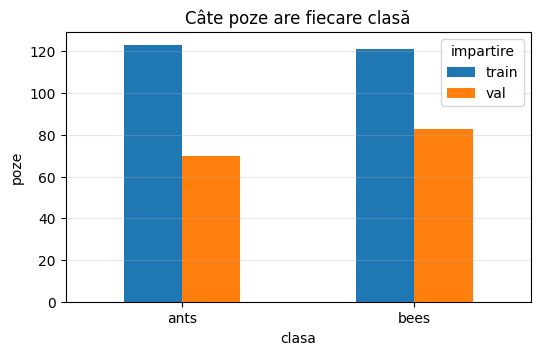

In [8]:
stricate = verifica_poze(CALE_DATE)            # 1. mută deoparte pozele care nu se deschid
duplicate = gaseste_duplicate(CALE_DATE)        # 2. caută poze identice în train și val

# 3. tabel cu numărul de poze + ce procent din fiecare clasă e în validare
tabel_poze = numara_poze(CALE_DATE)
tabel_poze["total"] = tabel_poze.sum(axis=1)
tabel_poze["% val"] = (tabel_poze["val"] / tabel_poze["total"]).map("{:.0%}".format)
display(tabel_poze)

# același tabel, ca grafic cu bare
ax = numara_poze(CALE_DATE).plot.bar(rot=0, figsize=(6, 3.5), title="Câte poze are fiecare clasă")
ax.set_ylabel("poze"); ax.grid(axis="y", alpha=0.3)
plt.show()

**Observații:** nu am găsit nicio poză stricată și niciun duplicat între train și val. Clasele sunt aproape echilibrate (123 de furnici și 121 de albine în train), deci acuratețea este o metrică potrivită. Împărțirea train/val este de aproximativ 61% / 39%. Validarea este deci mai mare decât în împărțirea obișnuită 80/20, ceea ce face estimarea acurateței mai stabilă.

### 2.3 Explorare: cum arată pozele?
Afișez câte 6 poze din fiecare clasă, un tabel cu statisticile mărimilor (medie, minim, maxim) și un grafic cu lățimea și înălțimea fiecărei poze. Linia punctată marchează 224 px, mărimea cu care lucrează ResNet18.

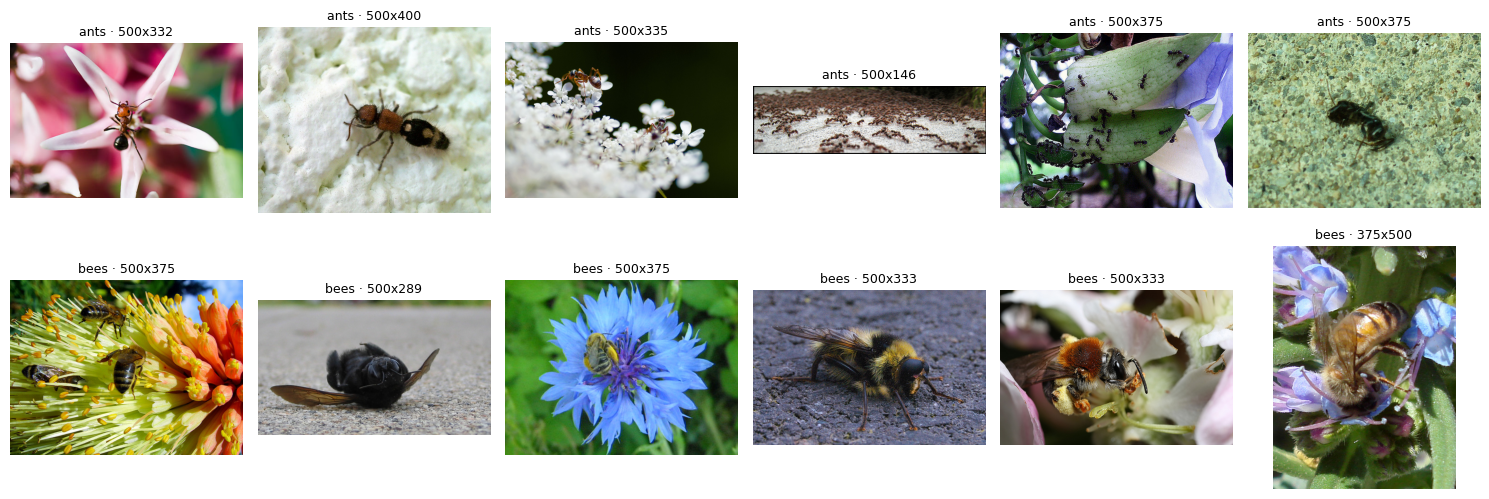

latime                                                   inaltime  \
       count   mean    std    min    25%    50%    75%     max    count   
clasa                                                                     
ants   123.0  482.0  121.0  193.0  500.0  500.0  500.0  1488.0    123.0   
bees   121.0  486.0   42.0  311.0  500.0  500.0  500.0   500.0    121.0   

                                                         
        mean    std    min    25%    50%    75%     max  
clasa                                                    
ants   384.0  168.0  130.0  333.0  375.0  404.0  1984.0  
bees   386.0   66.0  173.0  333.0  374.0  432.0   500.0

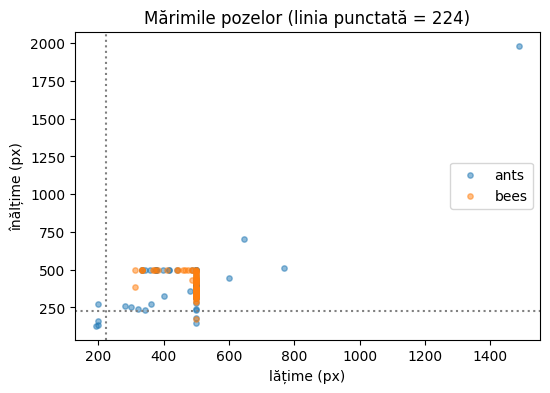

In [9]:
CLASE = sorted(os.listdir(f"{CALE_DATE}/train"))     # numele claselor = numele folderelor: ['ants', 'bees']
arata_mostre(CALE_DATE, CLASE, n=6)

dim = statistici_dimensiuni(CALE_DATE)                # lățimea și înălțimea fiecărei poze din train
display(dim.groupby("clasa")[["latime", "inaltime"]].describe().round(0))

# Fiecare punct = o poză (lățime, înălțime)
plt.figure(figsize=(6, 4))
for clasa, grup in dim.groupby("clasa"):
    plt.scatter(grup["latime"], grup["inaltime"], alpha=0.5, label=clasa, s=15)
plt.axvline(224, color="gray", ls=":"); plt.axhline(224, color="gray", ls=":")
plt.xlabel("lățime (px)"); plt.ylabel("înălțime (px)"); plt.title("Mărimile pozelor (linia punctată = 224)")
plt.legend(); plt.show()

**Observații:** pozele au mărimi și proporții diferite (cele mai multe au 500 px lățime, cea mai lată are 1488 px), iar ResNet18 primește imagini de `[3, 224, 224]`. De aceea toate pozele trec prin `Resize` + `CenterCrop` la validare și prin `RandomResizedCrop` la antrenare. În multe poze insecta este mică, iar fundalul (flori, frunze, pământ) ocupă cea mai mare parte din imagine. Mă aștept ca modelul să greșească mai ales la astfel de poze.

### 2.4 Transformări și augmentare
- **Validare:** aduc poza doar la formatul cerut de ResNet18: `Resize(256)` → `CenterCrop(224)` → normalizare cu media și deviația standard din ImageNet.
- **Antrenare:** în plus, la fiecare epocă poza este modificată puțin, la întâmplare (**augmentare**): decupare cu zoom, oglindire stânga-dreapta și schimbări mici de luminozitate și contrast. Astfel modelul vede la fiecare epocă variante noi ale acelorași poze.

Am ales doar augmentări **plauzibile**: o furnică fotografiată din alt unghi sau la altă lumină este tot o furnică. Nu am folosit rotiri de 180° sau întoarcere sus-jos, pentru că în pozele reale insectele apar rar așa. Nu am folosit nici schimbări mari de culoare, pentru că dungile galben-negru sunt un indiciu important pentru albine.

În celula următoare:
1. aleg arhitectura (`resnet18`), numărul de epoci (5) și mărimea lotului (16);
2. creez transformările;
3. încarc pozele cu `ImageFolder`, care ia eticheta fiecărei poze din numele folderului; clasele primesc numere în ordine alfabetică (`ants` = 0, `bees` = 1);
4. grupez pozele în loturi cu `DataLoader`; la train, ordinea se amestecă la fiecare epocă;
5. afișez o poză și 5 variante augmentate ale ei.

validare: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
clase: ['ants', 'bees'] | etichete: {'ants': 0, 'bees': 1}
train: 244 | val: 153
un lot: (16, 3, 224, 224) | etichete: [0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0]


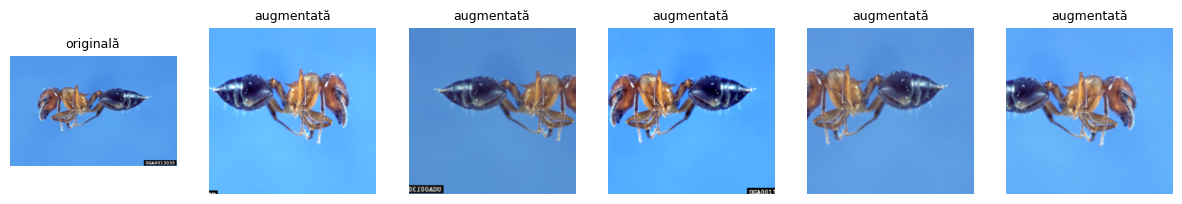

In [10]:
ARHITECTURA = "resnet18"     # modelul pre-antrenat de la care pornesc
EPOCI = 5                    # de câte ori trece modelul prin toate pozele de antrenare
BATCH = 16                   # câte poze vede modelul o dată (un lot)

transform_train, transform_val = transformari_pentru(ARHITECTURA)
print("validare:", transform_val)                     # pașii preprocesării de validare

# ImageFolder citește pozele și eticheta fiecăreia din numele folderului
date_train = datasets.ImageFolder(f"{CALE_DATE}/train", transform=transform_train)
date_val = datasets.ImageFolder(f"{CALE_DATE}/val", transform=transform_val)
CLASE = date_train.classes
print("clase:", CLASE, "| etichete:", date_train.class_to_idx)
print("train:", len(date_train), "| val:", len(date_val))

# DataLoader: împarte pozele în loturi (shuffle=True = le amestecă la fiecare epocă)
g = torch.Generator().manual_seed(SEED)               # amestecarea e și ea reproductibilă
train_loader = torch.utils.data.DataLoader(date_train, batch_size=BATCH, shuffle=True,
                                           num_workers=NUM_WORKERS, generator=g)
val_loader = torch.utils.data.DataLoader(date_val, batch_size=32, num_workers=NUM_WORKERS)
x, y = next(iter(train_loader))                       # luăm un lot, doar ca să vedem forma
print("un lot:", tuple(x.shape), "| etichete:", y.tolist())   # (16, 3, 224, 224) = 16 poze, 3 culori, 224x224

# Prima poză din train: originalul + 5 variante augmentate (de fiecare dată altfel)
poza = Image.open(date_train.imgs[0][0]).convert("RGB")
fig, axe = plt.subplots(1, 6, figsize=(15, 3))
axe[0].imshow(poza); axe[0].set_title("originală", fontsize=9); axe[0].axis("off")
for ax in axe[1:]:
    arata_tensor(transform_train(poza), ax, "augmentată")
plt.show()

### 2.5 Aceleași date, citite dintr-un CSV
Datele pot veni și sub forma unui tabel cu două coloane, `fisier` și `eticheta` (format folosit des pe Kaggle). Pentru acest caz am scris un **Dataset propriu**, adică o clasă care îi spune lui PyTorch:
- câte exemple are (`__len__`);
- cum citește exemplul cu numărul `i` (`__getitem__`), adică perechea (tensorul imaginii, numărul clasei).

Verific apoi că `etichete_val.csv` conține exact aceleași perechi (poză, etichetă) ca folderele de validare. Dacă fișierul CSV nu există, îl generez din foldere.

In [11]:
class DatasetDinCSV(torch.utils.data.Dataset):
    def __init__(self, cale_csv, transform):
        self.tabel = pd.read_csv(cale_csv)                       # coloane: fisier, eticheta
        self.clase = sorted(self.tabel["eticheta"].unique())     # aceeași ordine alfabetică ca ImageFolder
        self.transform = transform
    def __len__(self):                                   # câte exemple avem
        return len(self.tabel)
    def __getitem__(self, i):                            # cum citim exemplul cu numărul i
        rand = self.tabel.iloc[i]
        img = Image.open(rand["fisier"]).convert("RGB")
        return self.transform(img), self.clase.index(rand["eticheta"])   # (tensor, număr clasă)

# Dacă CSV-ul nu există, îl construim din foldere (în proiectele reale îl primești gata făcut)
if not os.path.exists("etichete_val.csv"):
    pd.DataFrame([{"fisier": c, "eticheta": CLASE[e]} for c, e in date_val.imgs]).to_csv("etichete_val.csv", index=False)

date_csv = DatasetDinCSV("etichete_val.csv", transform_val)
display(date_csv.tabel["eticheta"].value_counts().to_frame("poze"))

# Comparăm: {fișier: etichetă} din foldere vs din CSV
din_foldere = {os.path.normpath(c): CLASE[e] for c, e in date_val.imgs}
din_csv = {os.path.normpath(r.fisier): r.eticheta for r in date_csv.tabel.itertuples()}
print("CSV și folderele sunt identice:", din_foldere == din_csv)
x0, y0 = date_csv[0]
print("primul exemplu din CSV:", tuple(x0.shape), "eticheta", y0, f"({date_csv.clase[y0]})")

,poze
eticheta,
bees,83
ants,70


CSV și folderele sunt identice: True
primul exemplu din CSV: (3, 224, 224) eticheta 0 (ants)


## 3 · Baseline: „ghicesc mereu clasa mare”
Un model trebuie comparat cu ceva. Cel mai simplu „model” nu se uită deloc la poză: răspunde mereu cu clasa care apare cel mai des în train. Un model bun trebuie să-l depășească clar.

In [12]:
nr_train = np.bincount(date_train.targets)      # câte poze are fiecare clasă în train
clasa_mare = int(nr_train.argmax())             # clasa cu cele mai multe poze în train
y_val = np.array(date_val.targets)              # etichetele reale din validare
acc_baseline = (y_val == clasa_mare).mean()     # cât de des ar nimeri „mereu clasa mare”

print("poze train pe clasă:", dict(zip(CLASE, nr_train)))
print(f"Baseline: răspunde mereu '{CLASE[clasa_mare]}' → acuratețe validare {acc_baseline:.1%}")
print(f"(Dacă ar ghici clasa mare din VAL, '{CLASE[np.bincount(y_val).argmax()]}', ar avea "
      f"{np.bincount(y_val).max() / len(y_val):.1%}. Dar asta ar însemna să trișăm: ne-am uita la validare.)")

poze train pe clasă: {'ants': np.int64(123), 'bees': np.int64(121)}
Baseline: răspunde mereu 'ants' → acuratețe validare 45.8%
(Dacă ar ghici clasa mare din VAL, 'bees', ar avea 54.2%. Dar asta ar însemna să trișăm: ne-am uita la validare.)


**Observație:** în train sunt puțin mai multe furnici (123 față de 121), dar în validare sunt mai multe albine (83 față de 70). De aceea baseline-ul obține **45,8%**, sub 50%. Chiar și cea mai bună alegere fără să te uiți la poze (mereu „albină”) ar da doar 54,2%.

## 4 · Modele

### 4.1 Strategia 1: feature extraction
Încarc ResNet18 pre-antrenat, **înghețat** în întregime, și înlocuiesc doar ultimul strat `fc` (care avea 1000 de ieșiri, câte una pentru fiecare clasă din ImageNet) cu un strat nou cu **2 ieșiri**. Se antrenează doar 1.026 de parametri din 11,2 milioane.

Funcția `ruleaza_experiment` construiește modelul, afișează câți parametri se antrenează și, după fiecare epocă, loss-ul și acuratețea pe train și pe validare.

In [13]:
model_fe, istoric_fe, acc_fe = ruleaza_experiment(ARHITECTURA, "feature_extraction", EPOCI,
                                                  train_loader, val_loader, len(CLASE))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 37.5MB/s]


parametri antrenați: 1,026 din 11,177,538 (0.01%)
epoca 1: loss 0.578 | acuratețe train 0.697 | acuratețe validare 0.889  (4s)
epoca 2: loss 0.378 | acuratețe train 0.873 | acuratețe validare 0.935  (3s)
epoca 3: loss 0.299 | acuratețe train 0.885 | acuratețe validare 0.915  (7s)
epoca 4: loss 0.252 | acuratețe train 0.906 | acuratețe validare 0.915  (5s)
epoca 5: loss 0.241 | acuratețe train 0.898 | acuratețe validare 0.935  (3s)
→ resnet18 · feature_extraction: acuratețe validare 93.5% în 23s



### 4.2 Strategia 2: fine-tuning
Pornesc tot de la ResNet18 pre-antrenat, dar **dezgheț** și ultimul bloc convoluțional (`layer4`), ca modelul să se adapteze mai mult la furnici și albine. Folosesc o rată de învățare de 10 ori mai mică (`1e-4`), ca să nu stric ce a învățat modelul pe ImageNet. Aici se antrenează 8,4 milioane de parametri (75% din model).

In [14]:
model_ft, istoric_ft, acc_ft = ruleaza_experiment(ARHITECTURA, "fine_tuning", EPOCI,
                                                  train_loader, val_loader, len(CLASE))

parametri antrenați: 8,394,754 din 11,177,538 (75.10%)
epoca 1: loss 0.361 | acuratețe train 0.828 | acuratețe validare 0.928  (4s)
epoca 2: loss 0.121 | acuratețe train 0.955 | acuratețe validare 0.928  (3s)
epoca 3: loss 0.079 | acuratețe train 0.980 | acuratețe validare 0.935  (3s)
epoca 4: loss 0.039 | acuratețe train 0.996 | acuratețe validare 0.941  (3s)
epoca 5: loss 0.037 | acuratețe train 0.992 | acuratețe validare 0.948  (4s)
→ resnet18 · fine_tuning: acuratețe validare 94.8% în 19s



### 4.3 De la zero, fără transfer learning
Ca să văd cât contează pre-antrenarea, aceeași arhitectură se poate antrena și cu **greutăți aleatoare**, fără ImageNet. Am pregătit experimentul, dar l-am lăsat oprit (`RULEAZA_DE_LA_ZERO = False`), pentru că durează mai mult. Cu atât de puține poze, rezultatul este slab: în exemplul de la curs, antrenarea de la zero a ajuns la aproximativ 69% după 5 epoci.

In [15]:
RULEAZA_DE_LA_ZERO = False      # True = rulează și antrenarea de la zero (durează mai mult)

acc_zero, istoric_zero = None, None
if RULEAZA_DE_LA_ZERO:
    fixeaza_seed()
    de_la_zero = models.get_model(ARHITECTURA, weights=None)        # weights=None -> greutăți aleatoare
    de_la_zero.fc = nn.Linear(de_la_zero.fc.in_features, len(CLASE))
    de_la_zero, istoric_zero = antreneaza(de_la_zero, train_loader, epoci=EPOCI, lr=1e-3, val_loader=val_loader)
    acc_zero = evalueaza(de_la_zero, val_loader)[0]

### 4.4 Comparație
Afișez curbele de învățare (cum au evoluat loss-ul și acuratețea de la o epocă la alta), un tabel și un grafic cu acuratețea fiecărui model față de baseline. La final aleg automat modelul cu cea mai mare acuratețe pe validare.

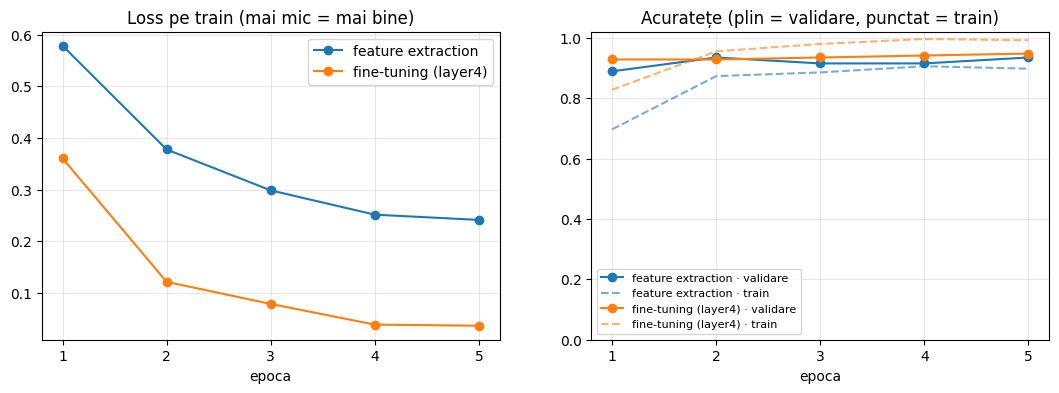

,model,acuratețe validare,parametri antrenați
0,baseline (clasa mare),45.8%,0
1,feature extraction,93.5%,"1,026"
2,fine-tuning (layer4),94.8%,"8,394,754"


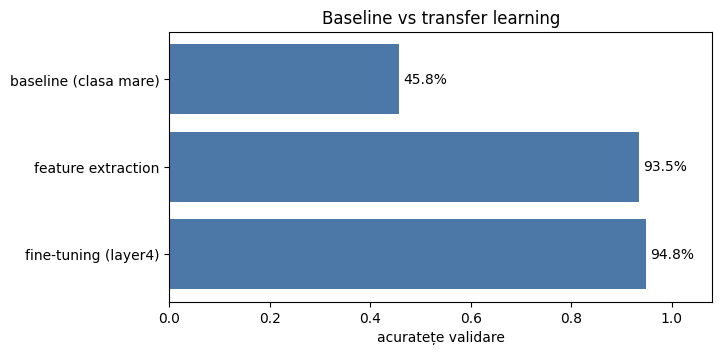

🏆 Modelul ales pentru evaluare și demo: fine_tuning


In [16]:
# Curbele de învățare
istorice = {"feature extraction": istoric_fe, "fine-tuning (layer4)": istoric_ft}
if istoric_zero is not None:
    istorice["de la zero"] = istoric_zero
deseneaza_istoric(istorice)

# Tabel cu rezultatele: (nume, acuratețe, câți parametri au fost antrenați)
rezultate = [("baseline (clasa mare)", acc_baseline, 0),
             ("feature extraction", acc_fe, sum(p.numel() for p in model_fe.parameters() if p.requires_grad)),
             ("fine-tuning (layer4)", acc_ft, sum(p.numel() for p in model_ft.parameters() if p.requires_grad))]
if acc_zero is not None:
    rezultate.insert(1, ("de la zero", acc_zero, sum(p.numel() for p in de_la_zero.parameters())))
comparatie = pd.DataFrame(rezultate, columns=["model", "acuratețe validare", "parametri antrenați"])
display(comparatie.style.format({"acuratețe validare": "{:.1%}", "parametri antrenați": "{:,}"}))

# Grafic cu bare orizontale
plt.figure(figsize=(7, 3.5))
bare = plt.barh(comparatie["model"], comparatie["acuratețe validare"], color="#4C78A8")
plt.bar_label(bare, labels=[f"{a:.1%}" for a in comparatie["acuratețe validare"]], padding=3)
plt.xlim(0, 1.08); plt.xlabel("acuratețe validare"); plt.gca().invert_yaxis()
plt.title("Baseline vs transfer learning"); plt.show()

# Aleg modelul cu acuratețea de validare cea mai mare
model_final, nume_final = (model_ft, "fine_tuning") if acc_ft >= acc_fe else (model_fe, "feature_extraction")
print(f"🏆 Modelul ales pentru evaluare și demo: {nume_final}")

**Interpretare:** ambele strategii depășesc clar baseline-ul (45,8%): feature extraction ajunge la **93,5%**, iar fine-tuning la **94,8%**. Diferența dintre ele este de doar **2 poze** din 153, deci nu pot spune sigur că fine-tuning-ul este mai bun: cu alt seed sau cu altă împărțire a datelor, ordinea s-ar putea schimba.

Curbele de învățare arată totuși o diferență:
- la **fine-tuning**, acuratețea pe train ajunge la 99%, iar pe validare rămâne în jur de 95%, deci modelul începe să memoreze pozele de antrenare (un început de **overfitting**);
- la **feature extraction**, acuratețea pe train (în jur de 90%) este chiar sub cea pe validare, pentru că pozele de antrenare sunt augmentate și deci mai greu de recunoscut.

Feature extraction antrenează de aproximativ 8.000 de ori mai puțini parametri (1.026 față de 8,4 milioane) și obține aproape același rezultat. Pentru un set mic de poze, asemănătoare cu cele din ImageNet, este o alegere foarte bună.

*Modelul final l-am ales tot după acuratețea pe validare, deci valoarea de 94,8% este puțin optimistă. Pentru o estimare complet corectă ar fi nevoie de un al treilea set, de test, folosit o singură dată, la final.*

## 5 · Evaluare: unde greșește modelul?
Acuratețea este o singură cifră. Ca să văd **unde** greșește modelul, îl rulez pe toate pozele de validare și afișez raportul de clasificare (precizie, recall și f1 pentru fiecare clasă) și matricea de confuzie.

Acuratețe validare (fine_tuning): 94.8%

              precision    recall  f1-score   support

        ants      0.931     0.957     0.944        70
        bees      0.963     0.940     0.951        83

    accuracy                          0.948       153
   macro avg      0.947     0.948     0.947       153
weighted avg      0.948     0.948     0.948       153



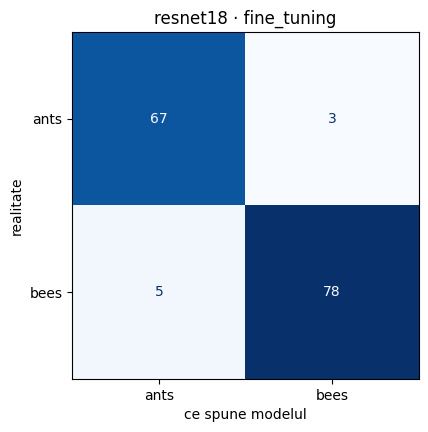

In [17]:
# probs = probabilitățile pentru fiecare poză și fiecare clasă
acc, y_true, y_pred, probs = evalueaza(model_final, val_loader)
print(f"Acuratețe validare ({nume_final}): {acc:.1%}\n")
print(classification_report(y_true, y_pred, target_names=CLASE, digits=3))
matrice_confuzie(y_true, y_pred, CLASE, f"{ARHITECTURA} · {nume_final}")

- **Precizia** pentru `bees`: din pozele pe care modelul le-a numit „albină”, câte erau într-adevăr albine.
- **Recall-ul** pentru `bees`: din toate albinele reale, câte a recunoscut modelul.
- **F1** este media armonică dintre precizie și recall.

**Rezultate:** pentru furnici, precizia este 93,1% și recall-ul 95,7%; pentru albine, precizia este 96,3% și recall-ul 94,0%. Matricea de confuzie arată 3 furnici clasificate ca albine și 5 albine clasificate ca furnici.

Mai jos afișez pozele greșite (deasupra fiecăreia: clasa reală, clasa prezisă și probabilitatea dată de model) și pozele la care modelul a ezitat cel mai mult.

Greșelile, începând cu cele la care modelul era cel mai sigur pe el:
Greșeli: 8 din 153


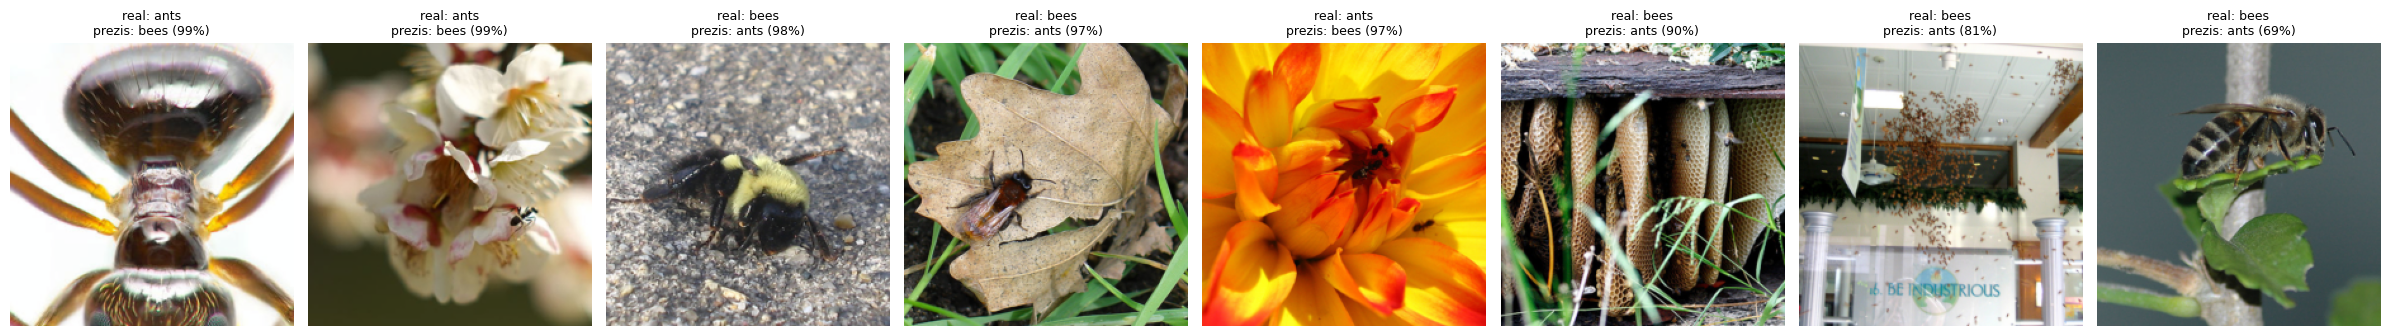

Pozele la care modelul a ezitat cel mai mult:


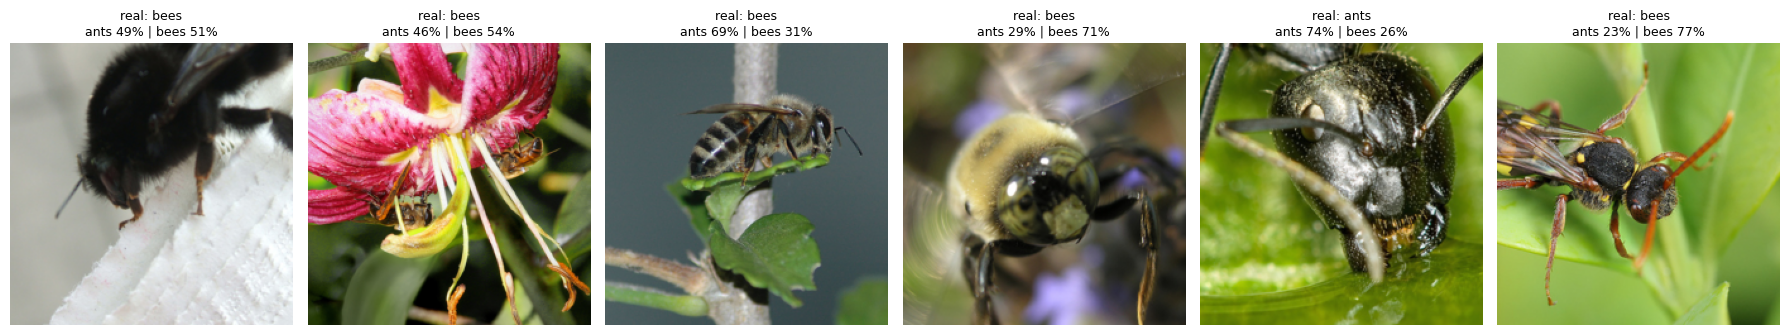

In [18]:
print("Greșelile, începând cu cele la care modelul era cel mai sigur pe el:")
fisiere_gresite = arata_greselile(date_val, y_true, y_pred, probs, CLASE)
print("Pozele la care modelul a ezitat cel mai mult:")
arata_nesigure(date_val, y_true, probs, CLASE)

**Ce au în comun greșelile** (8 din 153):
- **Fundalul contează prea mult.** Două furnici mici, fotografiate pe flori, au fost clasificate ca albine, cu 97–99% siguranță. Invers, albine fotografiate pe asfalt, pe o frunză uscată sau pe faguri au fost clasificate ca furnici. Modelul pare să fi învățat că „floare = albină” și „sol, frunze = furnică”.
- **Insecta este mică în poză.** În poza cu roiul de albine dintr-o clădire și în cea cu fagurii, insectele ocupă foarte puțin din imagine.
- **Unghiul neobișnuit.** O furnică fotografiată foarte de aproape, din spate, nu seamănă cu pozele obișnuite de furnici și a fost luată drept albină.
- **Bondarul.** Un bondar pe asfalt a fost luat drept furnică; bondarii arată destul de diferit de albinele obișnuite din set.

Cele mai multe greșeli vin din **date**, nu din model. Ca să le reduc, aș adăuga mai multe poze cu furnici pe flori și cu albine pe alte fundaluri, plus poze în care insecta este mică, și aș folosi o augmentare cu zoom mai puternic (`RandomResizedCrop` cu o scară mai mică).

## 6 · Demo: salvez modelul și îl folosesc pentru predicții
Salvez într-un fișier `.pt` greutățile modelului, lista claselor și numele arhitecturii. Apoi îl reîncarc, ca și cum l-aș folosi într-o aplicație separată, și fac predicții pe prima și pe ultima poză din validare. O poză nouă trece prin aceeași preprocesare ca pozele de validare, fără augmentare.

**Rezultat:** prima poză este recunoscută ca furnică (99,3%), iar ultima ca albină (99,99%).

Salvat: proiect2_furnici_albine.pt (44.8 MB)


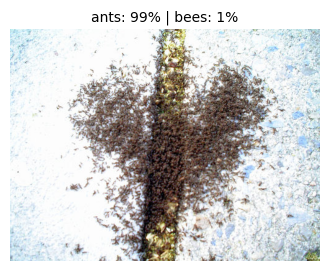

('ants', 0.992999792098999)


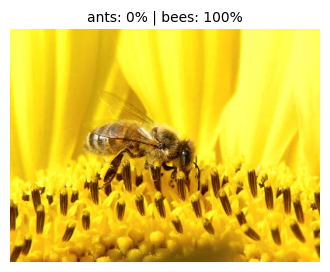

('bees', 0.9998619556427002)


In [19]:
CALE_MODEL = "proiect2_furnici_albine.pt"
salveaza_model(model_final, CLASE, ARHITECTURA, CALE_MODEL)

# ... mai târziu, în alt notebook sau într-o aplicație:
model_incarcat, clase_incarcate, arh = incarca_model(CALE_MODEL)
_, transform_predictie = transformari_pentru(arh)          # aceeași preprocesare ca la validare

for cale in [date_val.imgs[0][0], date_val.imgs[-1][0]]:
    print(prezice(cale, model_incarcat, clase_incarcate, transform_predictie))

## 7 · Concluzii
Mai jos am adunat cifrele importante ale proiectului.

In [22]:
print("REZUMATUL REZULTATELOR")
print(f"  • date: {len(date_train)} poze train, {len(date_val)} poze validare, {len(CLASE)} clase {CLASE}")
print(f"  • baseline (clasa mare din train): {acc_baseline:.1%}")
if acc_zero is not None:
    print(f"  • de la zero:                      {acc_zero:.1%}")
print(f"  • feature extraction:              {acc_fe:.1%}")
print(f"  • fine-tuning (layer4):            {acc_ft:.1%}")
print(f"  • greșeli ale modelului ales:      {int((y_true != y_pred).sum())} din {len(y_true)}")

REZUMATUL REZULTATELOR
  • date: 244 poze train, 153 poze validare, 2 clase ['ants', 'bees']
  • baseline (clasa mare din train): 45.8%
  • feature extraction:              93.5%
  • fine-tuning (layer4):            94.8%
  • greșeli ale modelului ales:      8 din 153


**Ce am învățat:**
1. Cu doar 244 de poze de antrenare, transfer learning-ul duce acuratețea de la 45,8% (baseline) la **94,8%**. Cea mai mare parte din „muncă” o face pre-antrenarea pe ImageNet.
2. **Feature extraction** (93,5%) este aproape la fel de bun ca **fine-tuning-ul** (94,8%), deși antrenează doar 1.026 de parametri. Explicația: furnicile și albinele seamănă cu pozele din ImageNet, care conține deja clase de insecte, deci caracteristicile învățate acolo se potrivesc bine.
3. Fine-tuning-ul arată un început de overfitting: 99% pe train față de 95% pe validare.
4. Greșelile vin mai ales din **date**: modelul se ia după fundal (flori → albină, sol → furnică) și greșește la insectele mici.

**Limitări:**
- setul de validare este mic: o poză înseamnă 0,65 puncte procentuale, deci diferența de 2 poze dintre strategii nu este sigură;
- am ales modelul final tot pe validare și am folosit un singur seed;
- modelul cunoaște doar 2 clase: softmax-ul împarte mereu 100% între „furnică” și „albină”, așa că pentru orice altă poză (de exemplu un câine) va răspunde tot una dintre ele.

**Pași următori:** mai multe poze, cu fundaluri variate; o clasă „altceva”; un set de test separat; mai multe seed-uri sau validare încrucișată; alte arhitecturi (`efficientnet_b0`, `mobilenet_v3_large`).

**Concluzie:** pentru o problemă cu puține poze, transfer learning-ul este alegerea potrivită. În mai puțin de un minut de antrenare am obținut un model care clasifică corect 145 din 153 de poze pe care nu le-a văzut la antrenare.